In [2]:
import kagglehub

path = kagglehub.dataset_download("hari31416/food-101")
print("Kaggle dataset path:", path)
from pathlib import Path
import copy
import json

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2


e:\cvllm\projects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kaggle dataset path: E:\kaggle_cache\datasets\hari31416\food-101\versions\1


In [3]:

print("PyTorch:", torch.__version__)
print("torchvision:", __import__("torchvision").__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


PyTorch: 2.15.0+cu134
torchvision: 0.29.2+cu134
CUDA available: True
Using: cuda


In [ ]:

# Point to the nested 'food-101' folder inside the downloaded path
dataset_dir = Path(path) / 'food-101'
train_dir = dataset_dir / "train"
validation_dir = dataset_dir / "validation"

print("Dataset:", dataset_dir)
print("Train exists:", train_dir.is_dir())
print("Validation exists:", validation_dir.is_dir())

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_data = datasets.ImageFolder(str(train_dir), transform=train_transform)
validation_data = datasets.ImageFolder(str(validation_dir), transform=eval_transform)

if train_data.class_to_idx != validation_data.class_to_idx:
    raise RuntimeError("Train and validation class mappings differ")

class_names = train_data.classes
num_classes = len(class_names)
batch_size = 32 if torch.cuda.is_available() else 16

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)
validation_loader = DataLoader(
    validation_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("Classes:", num_classes)
print("Training images:", len(train_data))
print("Validation images:", len(validation_data))
model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
model = model.to(device)


In [7]:

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
epochs = 10
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)


In [ ]:

print(model)
history = []
best_model_state = copy.deepcopy(model.state_dict())
best_validation_accuracy = 0.0

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    running_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum().item()

    model.eval()
    validation_correct = 0
    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            validation_correct += (predictions == labels).sum().item()

    train_loss = running_loss / len(train_data)
    train_accuracy = running_correct / len(train_data)
    validation_accuracy = validation_correct / len(validation_data)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_accuracy": validation_accuracy,
    })

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    scheduler.step()
    print(
        f"Epoch {epoch}/{epochs}: "
        f"loss={train_loss:.4f}, train_acc={train_accuracy:.4f}, "
        f"validation_acc={validation_accuracy:.4f}"
    )
checkpoint_path = Path("mobilenet_food101_best.pth")
metrics_path = Path("mobilenet_food101_metrics.json")

torch.save({
    "architecture": "mobilenet_v2",
    "num_classes": num_classes,
    "class_names": class_names,
    "class_to_idx": train_data.class_to_idx,
    "model_state_dict": best_model_state,
    "validation_accuracy": best_validation_accuracy,
    "history": history,
}, checkpoint_path)
metrics_path.write_text(json.dumps(history, indent=2), encoding="utf-8")

print("Saved checkpoint:", checkpoint_path.resolve())
print("Saved metrics:", metrics_path.resolve())
print("Best validation accuracy:", best_validation_accuracy)

In [6]:
from pathlib import Path
import json
import torch

# Define paths
checkpoint_path = Path("mobilenet_food101_interrupted_best.pth")
metrics_path = Path("mobilenet_food101_interrupted_metrics.json")

# Save the best completed epoch's model state currently in memory
torch.save({
    "architecture": "mobilenet_v2",
    "num_classes": num_classes,
    "class_names": class_names,
    "class_to_idx": train_data.class_to_idx,
    "model_state_dict": best_model_state,
    "validation_accuracy": best_validation_accuracy,
    "history": history,
}, checkpoint_path)

# Save the history metrics up to the last completed epoch
metrics_path.write_text(json.dumps(history, indent=2), encoding="utf-8")

print("Saved checkpoint to:", checkpoint_path.resolve())
print("Saved metrics to:", metrics_path.resolve())
print("Best validation accuracy saved:", best_validation_accuracy)

Saved checkpoint to: /content/mobilenet_food101_interrupted_best.pth
Saved metrics to: /content/mobilenet_food101_interrupted_metrics.json
Best validation accuracy saved: 0.7817821782178218


In [5]:
from pathlib import Path
import copy
import json
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2

checkpoint_path = Path("mobilenet_food101_interrupted_best.pth")
metrics_path = Path("mobilenet_food101_interrupted_metrics.json")

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False,
)

with metrics_path.open("r", encoding="utf-8") as file:
    history = json.load(file)

# Recreate and restore the architecture
model = mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    checkpoint["num_classes"],
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

start_epoch = len(history)
total_epochs = 10
remaining_epochs = total_epochs - start_epoch

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=remaining_epochs,
)

best_validation_accuracy = checkpoint["validation_accuracy"]
best_model_state = copy.deepcopy(model.state_dict())

print(f"Resuming at epoch {start_epoch + 1}")

Resuming at epoch 6


In [8]:
import torch
import copy
import json
from pathlib import Path

checkpoint_path = Path("mobilenet_food101_interrupted_best.pth")

if not checkpoint_path.exists():
    raise FileNotFoundError(f"No checkpoint found at {checkpoint_path}. Make sure to run the saving cell first.")

print("Loading checkpoint...")
checkpoint = torch.load(checkpoint_path, map_location=device)

# Restore model weights
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

# Re-initialize optimizer and scheduler to match state
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

# Load training history and find the next epoch to start from
history = checkpoint["history"]
completed_epochs = len(history)
start_epoch = completed_epochs + 1
best_validation_accuracy = checkpoint["validation_accuracy"]
best_model_state = copy.deepcopy(model.state_dict())

# Catch up scheduler steps
for _ in range(completed_epochs):
    scheduler.step()

print(f"Resuming training from epoch {start_epoch}/{epochs} (Best Validation Acc: {best_validation_accuracy:.4f})")

# Resume the training loop
for epoch in range(start_epoch, epochs + 1):
    model.train()
    running_loss = 0.0
    running_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        running_correct += (logits.argmax(dim=1) == labels).sum().item()

    model.eval()
    validation_correct = 0
    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            validation_correct += (predictions == labels).sum().item()

    train_loss = running_loss / len(train_data)
    train_accuracy = running_correct / len(train_data)
    validation_accuracy = validation_correct / len(validation_data)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_accuracy": validation_accuracy,
    })

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    scheduler.step()
    print(
        f"Epoch {epoch}/{epochs}: "
        f"loss={train_loss:.4f}, train_acc={train_accuracy:.4f}, "
        f"validation_acc={validation_accuracy:.4f}"
    )

# Save final checkpoint
final_checkpoint_path = Path("mobilenet_food101_final.pth")
final_metrics_path = Path("mobilenet_food101_final_metrics.json")

torch.save({
    "architecture": "mobilenet_v2",
    "num_classes": num_classes,
    "class_names": class_names,
    "class_to_idx": train_data.class_to_idx,
    "model_state_dict": best_model_state,
    "validation_accuracy": best_validation_accuracy,
    "history": history,
}, final_checkpoint_path)
final_metrics_path.write_text(json.dumps(history, indent=2), encoding="utf-8")

print("Saved final checkpoint:", final_checkpoint_path.resolve())
print("Best validation accuracy:", best_validation_accuracy)

Loading checkpoint...
Resuming training from epoch 6/10 (Best Validation Acc: 0.7818)


E:\Temp\ipykernel_40072\655527311.py:31: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


NameError: name 'train_loader' is not defined

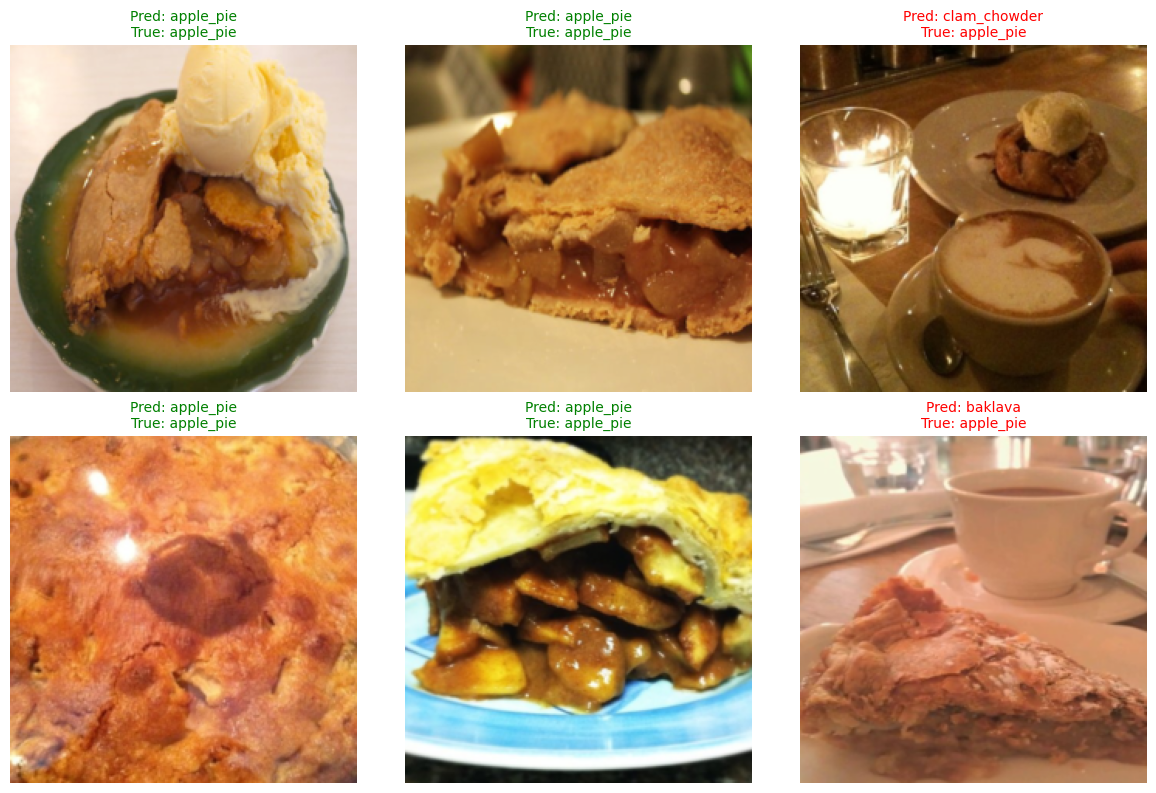

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Put model in evaluation mode
model.eval()

# Get a batch of validation images
images, labels = next(iter(validation_loader))
images_dev = images.to(device)

# Get predictions
with torch.no_grad():
    outputs = model(images_dev)
    preds = outputs.argmax(dim=1).cpu().numpy()

# Denormalize images for plotting
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Plot a grid of 6 sample images
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i in range(6):
    img = images[i].numpy().transpose((1, 2, 0))
    img = std * img + mean  # Denormalize
    img = np.clip(img, 0, 1)

    true_label = class_names[labels[i]]
    pred_label = class_names[preds[i]]

    axes[i].imshow(img)
    title_color = 'green' if true_label == pred_label else 'red'
    axes[i].set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=title_color, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()